# 4.0 – Recap: Initiation, Training and Evaluation

To recapitulate what we have learned about the AI Lifecycle from initiation to evaluation, we take face recognition as an end-to-end use case.

Face recognition systems are built on the assumption that each person has a similar face structure with indvidual characteristics. We all have a nose, a mouth, 2 ears, and cheeks, but they are composed slightly differently for everyone. This facilitates computerized face-matching. 

The work on face recognition has begun in the 1960's, the results of which are being used for security in various institutions and firms throughout the world. 

The images must be processed correctly for computer based face recognition. The face and its structural properties should be identified carefully, and the resulting image must be converted to two dimensional digital data.

![Img](./data/face_recognition.png)

For this task we use the dataset [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/) which contains more than 13,000 images of faces collected from the web. Each face has been labeled with the name of the person pictured and contains 50*37 pixels with differents shades of white, grey, and black.



## Loading the Data (Labeled Faces in the Wild Dataset)
The lfw_people dataset is from scikit-learn and does not require downloading any file from some external website. The code below will load the dataset.

**Mac users might need to do some additional steps to read the data**: Go to Macintosh HD > Applications > Python3.6 folder (or whatever version of python you're using) > double click on "Install Certificates.command" file

In [1]:
# load dataset
from sklearn.datasets import fetch_lfw_people

lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
lfw_people.data

array([[0.9973857 , 0.99607843, 0.9921568 , ..., 0.38169935, 0.38823533,
        0.3803922 ],
       [0.14771242, 0.19738562, 0.1751634 , ..., 0.45751634, 0.44444445,
        0.53594774],
       [0.34379086, 0.39477125, 0.49150327, ..., 0.709804  , 0.72156864,
        0.7163399 ],
       ...,
       [0.3633987 , 0.3372549 , 0.30718955, ..., 0.19738562, 0.22091503,
        0.19346406],
       [0.19346406, 0.24705882, 0.34248367, ..., 0.7346406 , 0.6640523 ,
        0.6117647 ],
       [0.11633987, 0.10196079, 0.1267974 , ..., 0.13333334, 0.13725491,
        0.2535948 ]], shape=(1288, 1850), dtype=float32)

In [2]:
# convert to pandas DataFrame
import pandas as pd

lfw_people_df = pd.DataFrame(data=lfw_people.data)
lfw_people_df['target'] = lfw_people.target
lfw_people_df.shape

(1288, 1851)

If the download does not work, you can use the csv file from the data folder.

In [ ]:
import pandas as pd
from pathlib import Path


candidate_paths = [
  Path("data/lfw_people.csv"),
  Path("04_Solution_4/data/lfw_people.csv"),
]


data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find data/lfw_people.csv. Start Jupyter in the repository root or 04_Solution_4.")

print(f"Loading: {data_path.resolve()}")

df = pd.read_csv(data_path, index_col = 0)
df.shape

## Plotting Faces

In [4]:
# Define a function to plot faces
import numpy as np 
import matplotlib.pyplot as plt
%matplotlib inline

def print_face(image):   
    plt.figure(figsize=(4,3))
    plt.imshow(np.reshape(image, (50,37)), cmap=plt.cm.gray)

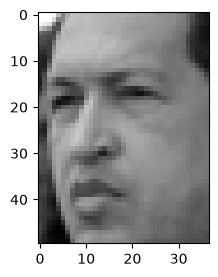

In [5]:
face_id = 0
print_face(lfw_people.data[face_id])

## Data Preprocessing

### **TASK: Data Preprocessing**

1. Explore and understand the dataset. Visualize relevant statistical properties of the dataset.
2. Transform the target column to a numeric feature.
3. Adapt the plotting function to plot an image from the dataset with the true target as plot title

In [6]:
# 1. data structure
lfw_people_df.head()

,0,1,2,3,4,5,6,7,8,9,...,1841,1842,1843,1844,1845,1846,1847,1848,1849,target
0,0.997386,0.996078,0.992157,0.966013,0.758170,0.569935,0.700654,0.794771,0.784314,0.767320,...,0.426144,0.422222,0.415686,0.401307,0.393464,0.390850,0.381699,0.388235,0.380392,5
1,0.147712,0.197386,0.175163,0.192157,0.385621,0.473203,0.543791,0.615686,0.671895,0.694118,...,0.239216,0.296732,0.307190,0.325490,0.410458,0.487582,0.457516,0.444444,0.535948,6
2,0.343791,0.394771,0.491503,0.555556,0.597386,0.611765,0.606536,0.626144,0.640523,0.652288,...,0.430065,0.379085,0.410458,0.498039,0.448366,0.481046,0.709804,0.721569,0.716340,3
3,0.047059,0.016993,0.023529,0.016993,0.031373,0.230065,0.677124,0.667974,0.641830,0.400000,...,0.749020,0.903268,0.915033,0.918954,0.925490,0.513725,0.065359,0.142484,0.201307,1
4,0.471895,0.458824,0.486275,0.499346,0.494118,0.513726,0.545098,0.543791,0.560784,0.581699,...,0.062745,0.019608,0.018301,0.018301,0.039216,0.036601,0.078431,0.250980,0.278431,0


In [7]:
# 1. statistical properties
lfw_people_df.describe()

,0,1,2,3,4,5,6,7,8,9,...,1841,1842,1843,1844,1845,1846,1847,1848,1849,target
count,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,...,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000,1288.000000
mean,0.355769,0.374626,0.412965,0.462963,0.507093,0.541963,0.567585,0.587089,0.605063,0.621473,...,0.388260,0.413324,0.447840,0.480924,0.496889,0.486948,0.465413,0.436856,0.404322,2.890528
std,0.180138,0.174567,0.169204,0.165087,0.159878,0.148425,0.142111,0.138726,0.135052,0.130857,...,0.201138,0.227058,0.249804,0.273326,0.285078,0.294930,0.303430,0.302333,0.303257,1.632890
min,0.000000,0.001307,0.001307,0.003922,0.005229,0.009150,0.009150,0.036601,0.039216,0.047059,...,0.007843,0.001307,0.003922,0.003922,0.002614,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.227124,0.252288,0.299020,0.359477,0.409150,0.449673,0.478105,0.500654,0.525163,0.539869,...,0.244118,0.244444,0.256209,0.259804,0.249673,0.220588,0.177451,0.157843,0.129412,2.000000
50%,0.339216,0.369935,0.415033,0.461438,0.509804,0.543137,0.571242,0.590850,0.609804,0.628758,...,0.371242,0.389542,0.420261,0.448366,0.477778,0.467320,0.438562,0.392157,0.330719,3.000000
75%,0.474510,0.486275,0.524183,0.574183,0.613072,0.639216,0.660131,0.678431,0.695425,0.707190,...,0.495425,0.548366,0.616013,0.695425,0.739869,0.745425,0.740196,0.699673,0.667974,4.000000
max,0.997386,0.996078,0.992157,0.968627,0.959477,0.968627,0.971242,0.989542,0.996078,0.993464,...,0.993464,0.990850,0.998693,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000


In [8]:
# Print different labels
lfw_people_df['target'].unique()

array([5, 6, 3, 1, 0, 4, 2])

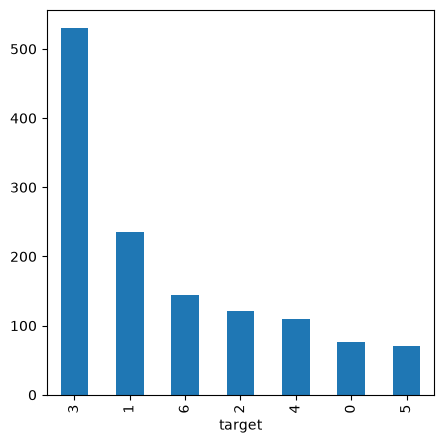

In [9]:
# Distribution of labels
lfw_people_df['target'].value_counts().plot(kind='bar', figsize=(5,5))
plt.show()

In [10]:
# Labels with names
for i in range(len(lfw_people.target_names)):
    print(f'Label {i}: {lfw_people.target_names[i]}')

Label 0: Ariel Sharon
Label 1: Colin Powell
Label 2: Donald Rumsfeld
Label 3: George W Bush
Label 4: Gerhard Schroeder
Label 5: Hugo Chavez
Label 6: Tony Blair


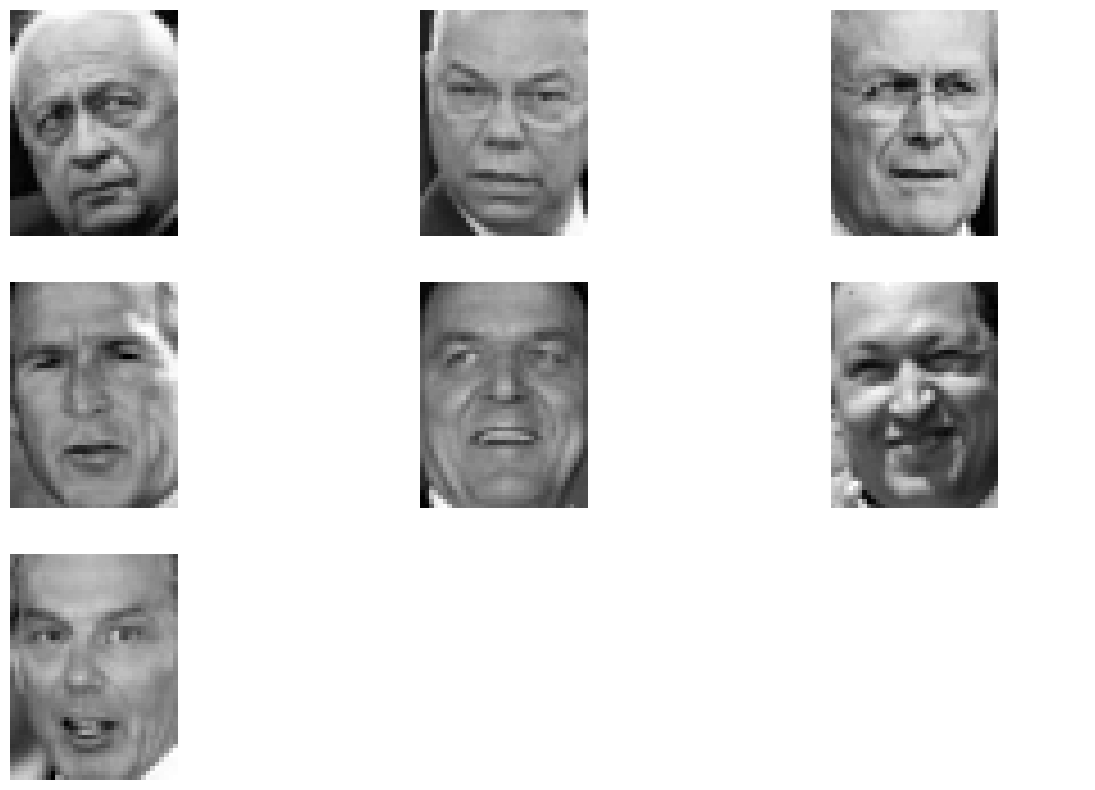

In [11]:
# Plot faces to each unique label
unique_targets = lfw_people_df.groupby('target').sample(n=1)

fig, axs = plt.subplots(3, 3, figsize=(15,10))
axs = axs.ravel()
for i in range(7):
    axs[i].imshow(np.reshape(unique_targets.iloc[i, :-1], (50,37)), cmap=plt.cm.gray)
    axs[i].axis('off')

for ax in axs[7:]:
    ax.axis('off')
plt.show()


In [12]:
# 2. Transform the target column to a numeric feature.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

print(lfw_people_df['target'].dtype)
print(lfw_people_df['target'].unique())

lfw_people_df['target'] = le.fit_transform(lfw_people_df['target'])

print(lfw_people_df['target'].dtype)
print(lfw_people_df['target'].unique())

int64
[5 6 3 1 0 4 2]
int64
[5 6 3 1 0 4 2]


If you did load the data from the provided CSV file, the target column would contain names. In this case this step is necessary, to get numeric labels.

In [13]:
# 3. Adapt the plotting function to plot an image from the dataset with the true target as plot title
def print_face_with_title(image, title):   
    plt.figure(figsize=(4,3))
    plt.imshow(np.reshape(image, (50,37)), cmap=plt.cm.gray)
    plt.title(title)

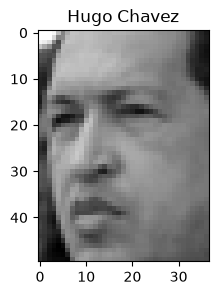

In [14]:
# 3. Print face with title
face_id = 0
print_face_with_title(lfw_people.data[face_id], lfw_people.target_names[lfw_people.target[face_id]])

## **TASK: PCA**

1. Define features and the target variable
2. Compute a PCA on the entire dataset and construct 150 features. *Note: use `svd_solver='randomized'` and `whiten=True`*

### 1. Define features and target variable

In [15]:
# 1. Define features and target variable
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

### 2. Compute PCA

In [16]:
# 2. Compute PCA
from sklearn.decomposition import PCA

# black&white images already share same scale (0-255), so standardization has minimal effect

# create parameterized PCA object
pca = PCA(n_components=150, svd_solver='randomized', whiten=True)
# fit PCA on training data
pca.fit(X)
# transform training data to a new dataset of PCA features
X_pca = pca.transform(X) # shape (n_samples, n_components)
print(X_pca.shape)

(1288, 150)


## What are Eigenfaces?

Eigenfaces is the name given to a set of eigenvectors when they are used in the computer vision problem of human face recognition. This approach for face recognition was developed in the late 1980's and is still used today.

You can imagine eigenfaces as a toolkit of generic faces that can be recombined to construct any face. Through PCA the set of generic faces within the toolkit can be minimized to represent the original training images with as little faces as possible. 

Let's look at some eigenfaces and test how well the eigenface representations can classify the true faces.

In [17]:
# The principal components from the PCA combine the 1850 original features into the 150 eigenfaces
eigenfaces = pca.components_ # shape (n_components, n_features)
eigenfaces.shape

(150, 1850)

How does a generic face from the toolkit look like?

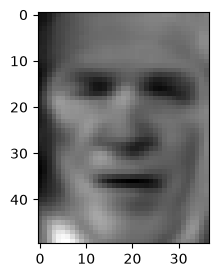

In [18]:
print_face(eigenfaces[8])

Eerie, right? Now let us put these eerie faces to use.

### **TASK: Classification with Eigenfaces**

1. Split the PCA data into appropriate subsets.
2. Train a SVM classification model using a `GridSearchCV` with the following grid:
```python
param_grid = {'C': [1e3, 5e3, 1e4, 5e4, 1e5],
                 'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.1] }
```
3. Choose the best performing model and explain your choice.
4. Train an optimal final model version
5. Evaluate the final model's performance and compare it to a different parameter combination.
6. Visualize some predictions with your adapted plotting function. (*Hint: You can reconstruct the original dimensionality of the test set using ``pca.inverse_transform``*)

### 1. Split data into appropriate subsets
We ideally split **before** computing PCA. Otherwise we 'leak' some information about our test data.

In [19]:
# 1. Split the PCA data into training, validation, and test data subsets.
from sklearn.model_selection import train_test_split

# We don't want to include any information about the test set during training or hyperparameter tuning.
# Therefore, we first split off the test set from the entire dataset, and then split the remaining data into training and validation sets and use only the training set for PCA fitting and model training.

# Test set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train set: X_train_val (64%) and validation set: X_val (16%)
X_train_val, X_val, y_train_val, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

# We use stratified splitting (based on y == the target label) to ensure that the class distribution is similar in all subsets.

In [20]:
# Initialize PCA
pca_val = PCA(n_components=150, svd_solver='randomized', whiten=True)

# Fit pca on trainig data and transform data to a new dataset of PCA features
pca_val.fit(X_train_val)
X_train_val = pca_val.transform(X_train_val)

# Don't refit on validation data! We want to evaluate how well our model generalizes to unseen data.
X_val = pca_val.transform(X_val)
print(X_train_val.shape, X_val.shape)

(824, 150) (206, 150)


### 2. Train a SVM classification model using a `GridSearchCV`

In [21]:
# 2. Train a SVM classification model using a `GridSearchCV`
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Train a SVM classification model
param_grid = {
    'C': [1e3, 5e3, 1e4, 5e4, 1e5],
    'gamma': [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.1]
}
clf = GridSearchCV(SVC(kernel='rbf', class_weight='balanced'), param_grid)
clf = clf.fit(X_train_val, y_train_val)

### 3. Choose the best performing model and explain your choice

In [22]:
# 3. Choose the best performing model and explain your choice.
val_score = clf.best_estimator_.score(X_val, y_val)
print(f'Accuracy score for best estimator based on validation set: {val_score:.4f}')
print('Best Parameters:', clf.best_params_)

Accuracy score for best estimator based on validation set: 0.8155
Best Parameters: {'C': 1000.0, 'gamma': 0.005}


We used a training set `X_train_val`to fit our classification model `clf` and a validation set `X_val` to evaluate (validate) the models parameters.<br>
We find:<br>
{'C': 1000.0, 'gamma': 0.005} is the best performing parameter combination on unseen data. We should use this combination to train our final model.<br>

---
Now, instead of using a train - validation split, we could do a similar hyperparameter search using cross-validation on the full training set. <br>
In this case, we basically do 5 different train - validation splits and train our model on each of them to get a more robust estimate of the best parameters.<br>
Of course, this is also more computationally expensive.

In [23]:
# Initialize PCA again
pca_crossval = PCA(n_components=150, svd_solver='randomized', whiten=True)

# Re-fit PCA on full training data (including validation set)
pca_crossval.fit(X_train)
X_train_pca = pca_crossval.transform(X_train)

In [24]:
# Use cv=5 for a 5-fold cross-validation on the full training set
# We don't have a dedicated validation set this time - instead each fold (split) acts as validation set once
clf_cv = GridSearchCV(SVC(kernel='rbf', class_weight='balanced'), param_grid, cv=5)
clf_cv = clf_cv.fit(X_train_pca, y_train)

# Best estimator score from cross validation (Average over all 5 folds)
val_score = clf_cv.best_score_
print(f'Accuracy score for best estimator based on cross validation: {val_score:.4f}')
print('Best Parameters:', clf_cv.best_params_)

Accuracy score for best estimator based on cross validation: 0.8223
Best Parameters: {'C': 1000.0, 'gamma': 0.005}


The best parameters are the ones that have the best score, averaged over all 5 splits.<br>
In this case we get {'C': 1000.0, 'gamma': 0.005} again.

**RESULT:** The best performing model based on validation (and cross-validation) is the model we get from the combination of parameters: {'C': 1000.0, 'gamma': 0.005}.<br>
So this is what we will train our final model on.

### 4. Train an optimized final model version

In [25]:
# 4. Train an optimized final model version

final_model = SVC(kernel='rbf', class_weight='balanced', C=clf.best_params_['C'], gamma=clf.best_params_['gamma'])
final_model.fit(X_train_pca, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000.0
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.005
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### 5. Evaluate the final model's performance

In [26]:
# Transform test data using PCA
X_test_pca = pca_crossval.transform(X_test)
X_test_pca.shape

(258, 150)

In [27]:
# 5.1. Evaluate the final model's performance
from sklearn.metrics import confusion_matrix

# Helper function to plot confusion matrix with legends and numbers of predictions
def plot_confusion_matrix(cm, class_names):
    plt.imshow(cm, cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=90)
    plt.yticks(tick_marks, class_names)

    # Add numbers to each cell
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, format(cm[i, j], 'd'), horizontalalignment="center", color="black"
            )

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

In [28]:
# Quantitative evaluation of the model quality on the test set
print("Accuracy of optimal model:", final_model.score(X_test_pca, y_test))

# Get predictions from the final model
y_pred = final_model.predict(X_test_pca)

# Compute confusion matrix from predictions and true labels
cm = confusion_matrix(y_test, y_pred)
print(cm)

Accuracy of optimal model: 0.8682170542635659
[[ 10   0   1   5   0   0   0]
 [  0  46   0   1   0   0   0]
 [  0   1  17   5   1   0   0]
 [  0   3   0 103   0   0   0]
 [  0   1   1   2  16   0   2]
 [  0   0   0   4   0  10   0]
 [  0   1   0   6   0   0  22]]


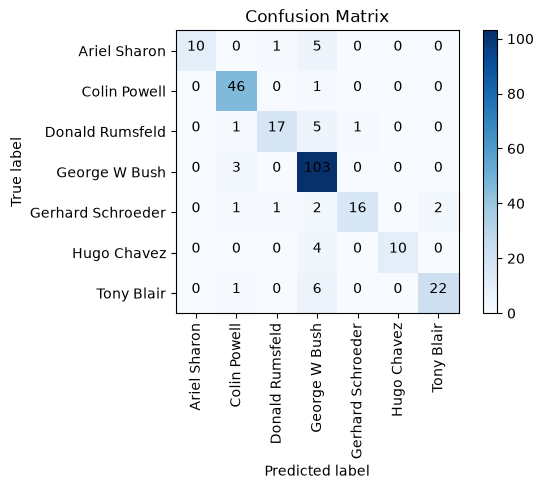

In [29]:
# Plot confusion matrix
plot_confusion_matrix(cm, lfw_people.target_names)

Our optimized model has an accuracy of around 86% and seems to make little errors.<br>
It seems to have a little problem distinguishing between Tony Blair and Donald Rumsfeld.

In [30]:
# 5.2. Compare it to a different parameter combination.
# We select the worst performing parameters from the grid search results
worst_parameters = clf.cv_results_['params'][np.argmin(clf.cv_results_['mean_test_score'])]
print("Worst Parameters:", worst_parameters)

# Fit model with worst parameters
clf_worst = SVC(kernel='rbf', class_weight='balanced', C=worst_parameters['C'], gamma=worst_parameters['gamma'])
clf_worst.fit(X_train_pca, y_train)

Worst Parameters: {'C': 1000.0, 'gamma': 0.1}


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000.0
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [31]:
# Quantitative evaluation of the model quality on the test set
print("Accuracy of worse model:", clf_worst.score(X_test_pca, y_test))

y_pred_worst = clf_worst.predict(X_test_pca)
cm_worst = confusion_matrix(y_test, y_pred_worst)
print(cm_worst)

Accuracy of worse model: 0.4108527131782946
[[  0   0   0  16   0   0   0]
 [  0   0   0  47   0   0   0]
 [  0   0   0  24   0   0   0]
 [  0   0   0 106   0   0   0]
 [  0   0   0  22   0   0   0]
 [  0   0   0  14   0   0   0]
 [  0   0   0  29   0   0   0]]


In [32]:
from collections import Counter
# Most predicted name
most_common_name = Counter(y_pred_worst).most_common(1)[0]
print("Most predicted name by worse model:", most_common_name)

Most predicted name by worse model: ('George W Bush', 258)


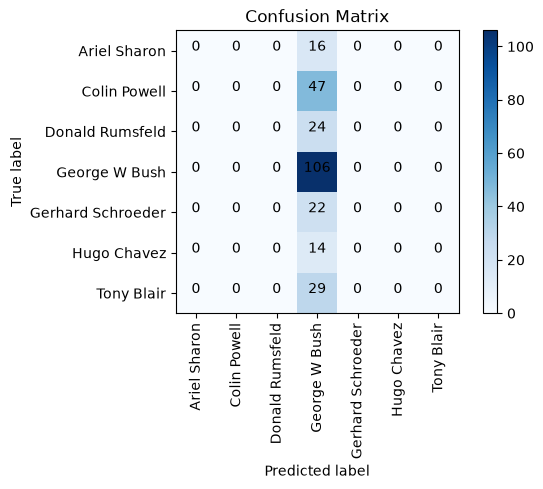

In [33]:
cm = confusion_matrix(y_test, y_pred_worst)
plot_confusion_matrix(cm, lfw_people.target_names)

The worst model seems to constantly predict George Bush.<br>
We can also see that the accuracy is around 41% - below half of what our optimized model had.

### 6. Visualize some of the predictions

Predicted person by optimal model:  Tony Blair
Predicted person by worst model:  George W Bush


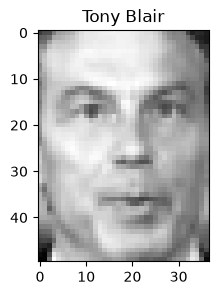

In [34]:
# 6. Visualize some of the predictions
# Select a random index from the test set
rand_index = np.random.randint(0, X_test.shape[0])
test_face = X_test.iloc[rand_index]

print("Predicted person by optimal model: ", y_pred[rand_index])
print("Predicted person by worst model: ", y_pred_worst[rand_index])

# Plot the face with true label and predictions
print_face_with_title(test_face, y_test.iloc[rand_index])

With ``pca.inverse_transform``, you can also get an approximation of what the model "sees".

Predicted person by optimal model:  Tony Blair
Predicted person by worst model:  George W Bush


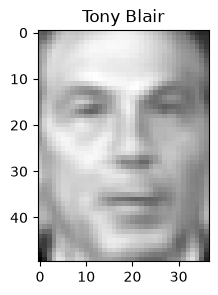

In [35]:
# 6. Visualize some of the predictions
# Reconstruct the original image dimensions with inverse PCA transform
test_face = pca_crossval.inverse_transform(X_test_pca[rand_index].reshape(1, -1)) # shape: (n_test, n_original_features)

# Print predictions
print("Predicted person by optimal model: ", y_pred[rand_index])
print("Predicted person by worst model: ", y_pred_worst[rand_index])

# Plot the face with true label and predictions
print_face_with_title(test_face, y_test.iloc[rand_index])